# Đánh giá hiệu năng RAG (Simple vs Complex Questions)
Notebook này vẽ biểu đồ cột so sánh độ chính xác của 3 thuật toán dựa trên file kết quả đánh giá (15 câu hỏi đơn giản vs 15 câu hỏi nâng cao).

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Đọc dữ liệu từ file CSV
df = pd.read_csv('doc\\Acc_rag.csv')
display(df.head(15))

,Query_Index,Question,Vector_Search_Acc(%),Sparse_Search_Acc(%),Advanced_Hybrid_Acc(%)
0,1,Dung lượng pin của iPhone 15 Pro Max là bao nh...,60,80,100
1,2,Samsung Galaxy S24 Ultra sử dụng chip gì?,80,60,80
2,3,Giá bán của iPhone 14 Pro hiện tại là bao nhiêu?,40,80,100
3,4,Màn hình của Xiaomi 14 có kích thước bao nhiêu...,60,60,80
4,5,Oppo Find X7 có hỗ trợ sạc nhanh bao nhiêu W?,80,60,100
5,6,Camera chính của Samsung S23 Ultra có độ phân ...,60,80,80
6,7,iPhone 13 có mấy màu sắc để lựa chọn?,60,40,80
7,8,iPad Pro M4 2024 có những tuỳ chọn dung lượng ...,80,60,100
8,9,Điện thoại Samsung nào có bút S-Pen tích hợp sẵn?,40,60,80
9,10,Xiaomi Redmi Note 13 Pro 5G ra mắt năm nào?,60,80,100


In [7]:
# Chia dữ liệu thành 2 nhóm: 15 câu đầu (Simple) và 15 câu sau (Complex)
simple_df = df.iloc[:15]
complex_df = df.iloc[15:]

# Tính trung bình độ chính xác cho từng nhóm
metrics = ['Vector_Search_Acc(%)', 'Sparse_Search_Acc(%)', 'Advanced_Hybrid_Acc(%)']

simple_means = simple_df[metrics].mean()
complex_means = complex_df[metrics].mean()

print("Trung bình 15 câu đơn giản:\n", simple_means)
print("\nTrung bình 15 câu phức tạp:\n", complex_means)

Trung bình 15 câu đơn giản:
 Vector_Search_Acc(%)      62.666667
Sparse_Search_Acc(%)      64.000000
Advanced_Hybrid_Acc(%)    88.000000
dtype: float64

Trung bình 15 câu phức tạp:
 Vector_Search_Acc(%)      58.666667
Sparse_Search_Acc(%)      49.333333
Advanced_Hybrid_Acc(%)    77.333333
dtype: float64


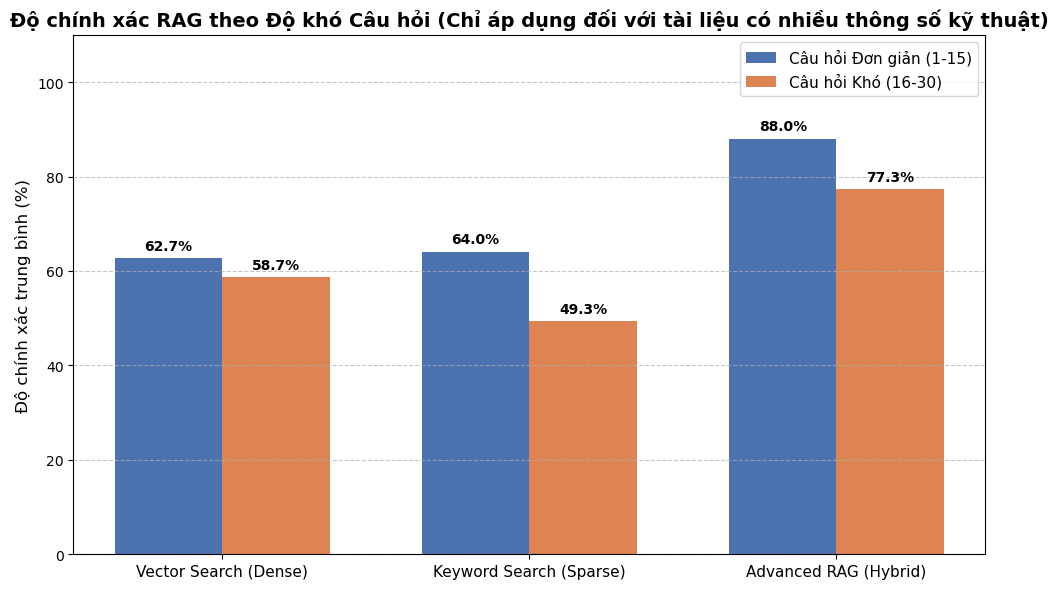

In [ ]:
# Vẽ biểu đồ cột nhóm (Grouped Bar Chart)
labels = ['Vector Search (Dense)', 'Keyword Search (Sparse)', 'Advanced RAG (Hybrid)']
simple_scores = simple_means.values
complex_scores = complex_means.values

x = np.arange(len(labels))  # Vị trí các nhóm
width = 0.35  # Độ rộng của cột

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, simple_scores, width, label='Câu hỏi Đơn giản (1-15)', color='#4C72B0')
rects2 = ax.bar(x + width/2, complex_scores, width, label='Câu hỏi Khó (16-30)', color='#DD8452')

# Thêm nhãn, tiêu đề
ax.set_ylabel('Độ chính xác trung bình (%)', fontsize=12)
ax.set_title('Độ chính xác RAG theo Độ khó Câu hỏi (Chỉ áp dụng đối với tài liệu có nhiều thông số kỹ thuật)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 110)
ax.legend(fontsize=11)

# Hàm hiển thị giá trị trên đầu mỗi cột
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points offset vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.savefig("doc\\plot.png", dpi=300, bbox_inches="tight") 
plt.show()